In [1]:
import zipfile
zip = zipfile.ZipFile("/content/drive/MyDrive/dateset/Fruits_Vegetables.zip")

In [2]:
zip.extractall("Fruits_Veg_Dataset")

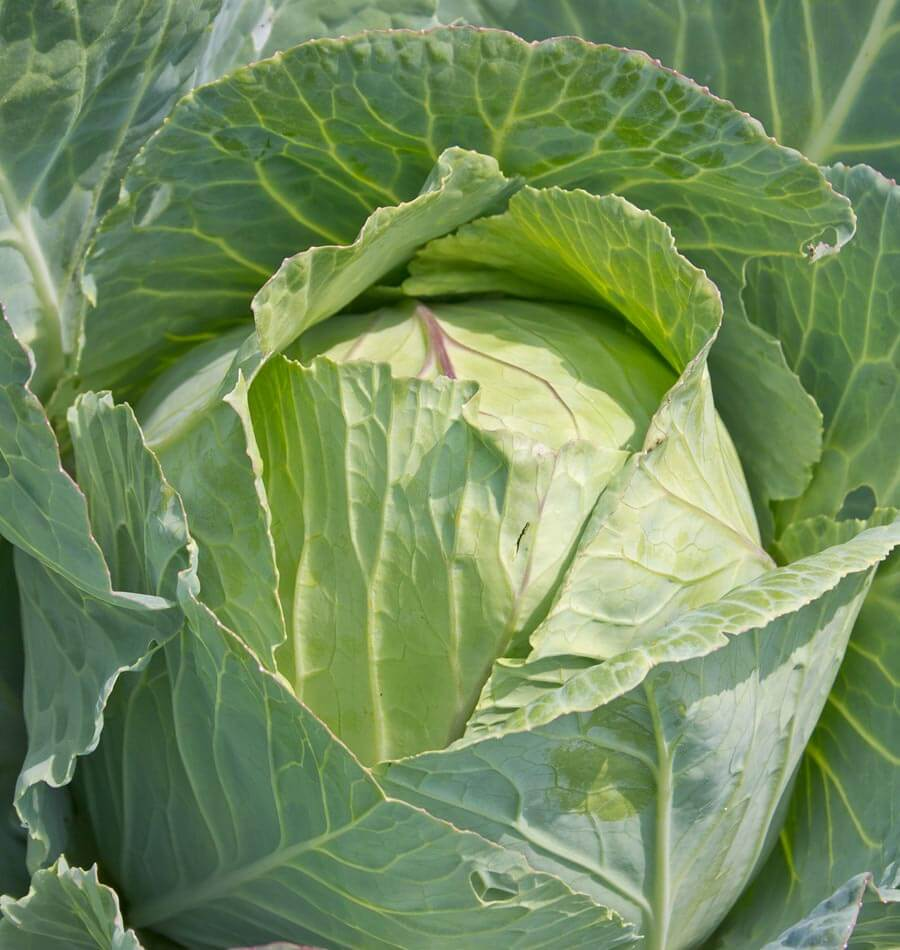

In [1]:
from PIL import Image
Image.open("/content/Fruits_Veg_Dataset/Fruits_Vegetables/train/cabbage/Image_11.jpg")

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [3]:
img_height = 180
img_weidth = 180

In [4]:
train_images = tf.keras.utils.image_dataset_from_directory(
    "/content/Fruits_Veg_Dataset/Fruits_Vegetables/train",
    image_size=(img_height,img_weidth),
    batch_size=32,
    shuffle=True,
    seed=42,
    validation_split=False
)

Found 3115 files belonging to 36 classes.


In [5]:
data_labels = train_images.class_names

In [6]:
test_images = tf.keras.utils.image_dataset_from_directory(
    "/content/Fruits_Veg_Dataset/Fruits_Vegetables/test",
    image_size=(img_height,img_weidth),
    batch_size=32,
    shuffle=True,
    seed=42,
    validation_split=False
)

Found 359 files belonging to 36 classes.


In [7]:
val_images = tf.keras.utils.image_dataset_from_directory(
    "/content/Fruits_Veg_Dataset/Fruits_Vegetables/validation",
    image_size=(img_height,img_weidth),
    batch_size=32,
    shuffle=True,
    seed=42,
    validation_split=False
)

Found 351 files belonging to 36 classes.


In [12]:
model = Sequential([
    layers.Rescaling(.1/255),
    layers.Conv2D(16,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(len(data_labels))
])


In [13]:
model.compile(optimizer="adam",loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=["accuracy"])

In [15]:
history = model.fit(train_images,validation_data=val_images,epochs=3,batch_size=32)

Epoch 1/3
98/98 ━━━━━━━━━━━━━━━━━━━━ 58s 588ms/step - accuracy: 0.4761 - loss: 1.7522 - val_accuracy: 0.6809 - val_loss: 1.1202
Epoch 2/3
98/98 ━━━━━━━━━━━━━━━━━━━━ 81s 572ms/step - accuracy: 0.5294 - loss: 1.5721 - val_accuracy: 0.7236 - val_loss: 0.9799
Epoch 3/3
98/98 ━━━━━━━━━━━━━━━━━━━━ 86s 613ms/step - accuracy: 0.5669 - loss: 1.4176 - val_accuracy: 0.7436 - val_loss: 0.9160


In [38]:
def predictor(img):
  image = img
  img = tf.keras.utils.load_img(img,target_size=(img_height,img_weidth))
  img_arry = tf.keras.utils.img_to_array(img)
  img = tf.expand_dims(img_arry,0)
  pred = model.predict(img)
  score = tf.nn.softmax(pred)
  return f"the provided img is an {data_labels[np.argmax(score)]},and model confidence is {np.max(score)*100}"

In [43]:
predictor("/content/lemon.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


'the provided img is an lemon,and model confidence is 58.925235748291016'

In [46]:
data_labels

['apple',
 'banana',
 'beetroot',
 'bell pepper',
 'cabbage',
 'capsicum',
 'carrot',
 'cauliflower',
 'chilli pepper',
 'corn',
 'cucumber',
 'eggplant',
 'garlic',
 'ginger',
 'grapes',
 'jalepeno',
 'kiwi',
 'lemon',
 'lettuce',
 'mango',
 'onion',
 'orange',
 'paprika',
 'pear',
 'peas',
 'pineapple',
 'pomegranate',
 'potato',
 'raddish',
 'soy beans',
 'spinach',
 'sweetcorn',
 'sweetpotato',
 'tomato',
 'turnip',
 'watermelon']

In [52]:
np.max(score)*100

np.float32(81.37858)

In [50]:
np.argmax(score)

np.int64(0)

In [53]:
model.save("Fruite_and_veg_model.keras")